# Synthetic SaaS experimentation workflow

4,230 generated user records demonstrate planning, fixed-horizon inference, assumed-prior Bayesian analysis, exploratory subgroups, covariate adjustment and a scorecard. No real users, revenue improvement or rollout decision are observed. See [REPORT.md](../REPORT.md).


In [1]:
import sys, yaml, json
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.abtest.simulate    import generate_experiment, simulate_pvalue_distribution
from src.abtest.power       import required_sample_size, mde_curve, power_by_sample_size
from src.abtest.frequentist import two_proportion_ztest, welch_ttest, sequential_test, segment_analysis
from src.abtest.bayesian    import probability_treatment_better, rope_decision, posterior_samples
from src.abtest.cuped       import apply_cuped_multi, cuped_variance_reduction_multi
from src.abtest.visualise   import (
    plot_power_curves, plot_posterior, plot_pvalue_distribution, plot_sequential_path,
    plot_segment_forest, plot_revenue_distribution, plot_metric_scorecard,
)

OUTPUTS = ROOT / 'outputs'
OUTPUTS.mkdir(exist_ok=True)

cfg = yaml.safe_load((ROOT / 'config' / 'experiment.yaml').read_text())
exp = cfg['experiment']
seq = cfg['sequential']
bay = cfg['bayesian']

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.4f}'.format)

print(f"Experiment : {exp['name']}")
print(f"Baseline   : {exp['baseline_activation_rate']:.0%} activation")
print(f"MDE        : {exp['mde']:.0%} relative lift")
print(f"Alpha / Power: {exp['alpha']} / {exp['power']}")

Experiment : saas_onboarding_wizard
Baseline   : 18% activation
MDE        : 20% relative lift
Alpha / Power: 0.05 / 0.8


## Normal-approximation planning

The two-proportion normal approximation gives 1,923 records per arm at baseline 18%, relative MDE 20%, alpha .05 and target power .8. This is not exact binomial sizing. The sensitivity table uses 1,923 rather than the buffered 2,115. MDE scales approximately as 1/sqrt(N).


In [2]:
n_required = required_sample_size(
    baseline_cvr=exp['baseline_activation_rate'],
    mde=exp['mde'],
    alpha=exp['alpha'],
    power=exp['power'],
)

print(f"Required per group : {n_required:,} users")
print(f"Total experiment   : {n_required * 2:,} users")
print()
print("Sensitivity check (power at various lifts):")
for lift in [0.10, 0.15, 0.20, 0.25, 0.30]:
    from scipy import stats as _stats
    p1 = exp['baseline_activation_rate']
    p2 = p1 * (1 + lift)
    se = np.sqrt(p1*(1-p1)/n_required + p2*(1-p2)/n_required)
    z  = (p2-p1)/se - _stats.norm.ppf(1 - exp['alpha']/2)
    pw = _stats.norm.cdf(z)
    print(f"  {lift:.0%} relative lift → {pw:.1%} power")

Required per group : 1,923 users
Total experiment   : 3,846 users

Sensitivity check (power at various lifts):
  10% relative lift → 29.7% power
  15% relative lift → 56.4% power
  20% relative lift → 80.1% power
  25% relative lift → 93.5% power
  30% relative lift → 98.5% power


Saved → outputs/power_curves.png


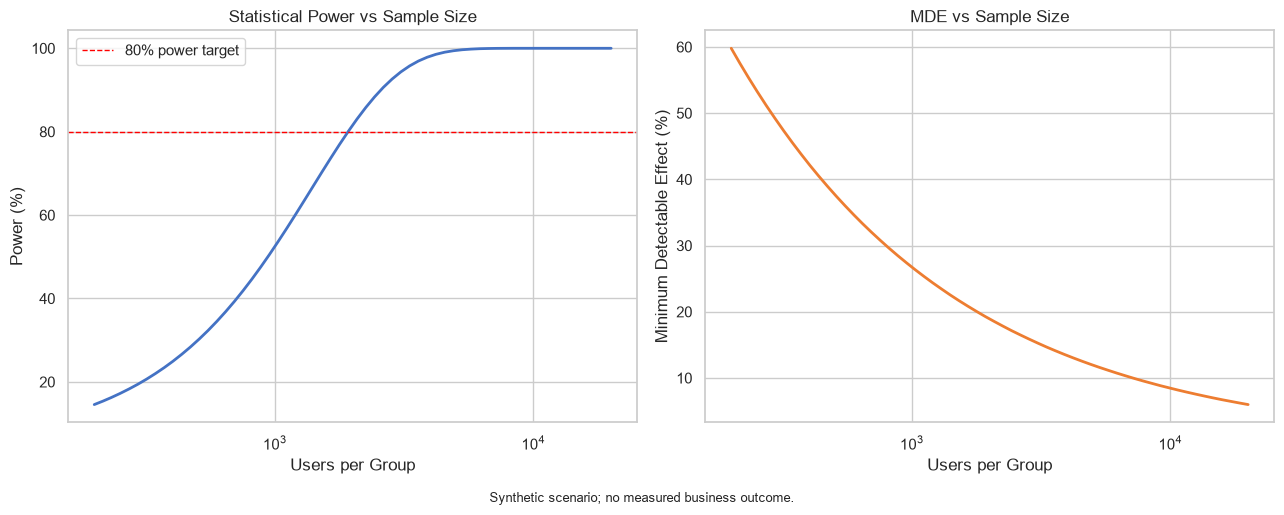

In [3]:
power_df = power_by_sample_size(
    baseline_cvr=exp['baseline_activation_rate'],
    true_lift=exp['mde'],
    n_range=(200, 20_000),
)
mde_df = mde_curve(
    baseline_cvr=exp['baseline_activation_rate'],
    n_per_group_range=(200, 20_000),
)

fig = plot_power_curves(power_df, mde_df, save_path=OUTPUTS / 'power_curves.png')
plt.show()
print(f"Saved → outputs/power_curves.png")

## Generated experiment records

The generator plants an aggregate relative activation effect of 25% before individual clipping, using company-size lift shapes that are rescaled to that target. The shape constants are not the realised segment effects. It adds 4 pp drop-off independently of activation. Acquisition channel is sampled independently and does not affect outcomes. Requested baseline scales the segment profile; generated rates can differ through clipping and sampling.


In [4]:
TRUE_LIFT = 0.25   # 25% relative lift planted in the simulator
n_users   = int(n_required * 2 * 1.10)   # required N per group × 2 arms × 1.10 buffer

df = generate_experiment(
    n_users=n_users,
    baseline_activation_rate=exp['baseline_activation_rate'],
    true_lift=TRUE_LIFT,
    traffic_split=exp['traffic_split'],
    seed=42,
)

print(f"Total users generated : {len(df):,}")
print(f"Per group             : ~{len(df)//2:,}")
print()

ctrl = df[df['variant'] == 'control']
trt  = df[df['variant'] == 'treatment']

summary = df.groupby('variant').agg(
    Users          = ('user_id',              'count'),
    Activated      = ('activated',            'sum'),
    Activation_Rate= ('activated',            'mean'),
    Avg_Revenue    = ('revenue',              'mean'),
    Day1_Dropoff   = ('day1_dropoff',         'mean'),
).round(4)
print(summary)

Total users generated : 4,230
Per group             : ~2,115

           Users  Activated  Activation_Rate  Avg_Revenue  Day1_Dropoff
variant                                                                
control     2115        395           0.1868       2.8456        0.3305
treatment   2115        482           0.2279       3.2665        0.3839


## Exploratory composition and covariates

Inspect generated group composition. The labels and covariate relationships are generator assumptions, not observed product behaviour.


In [5]:
# Segment composition
print("=== Segment composition (% of total) ===")
print(df['company_size'].value_counts(normalize=True).map('{:.1%}'.format).to_string())
print()
print(df['acquisition_channel'].value_counts(normalize=True).map('{:.1%}'.format).to_string())
print()

# Raw activation by segment × variant
print("=== Activation rate by company_size and variant ===")
pivot = df.groupby(['company_size', 'variant'])['activated'].mean().unstack()
pivot['delta_pp'] = (pivot['treatment'] - pivot['control']).round(4)
pivot['rel_lift']  = (pivot['delta_pp'] / pivot['control']).map('{:.1%}'.format)
print(pivot.round(4))
print()

# Pre-experiment covariate distributions
print("=== Pre-experiment covariate summary ===")
print(df.groupby('variant')[['pre_exp_sessions','pre_exp_feature_depth']].describe().round(2))

=== Segment composition (% of total) ===
company_size
small_team    45.7%
solo          39.0%
large_team    15.3%

acquisition_channel
organic     50.3%
paid        35.2%
referral    14.5%

=== Activation rate by company_size and variant ===
variant       control  treatment  delta_pp rel_lift
company_size                                       
large_team     0.3030     0.3829    0.0799    26.4%
small_team     0.2159     0.2697    0.0538    24.9%
solo           0.1083     0.1162    0.0079     7.3%

=== Pre-experiment covariate summary ===
          pre_exp_sessions                ...                      
                     count   mean    std  ...    50%    75%     max
variant                                   ...                      
control          2115.0000 7.1600 4.5700  ... 4.0000 5.7000 10.0000
treatment        2115.0000 7.1000 4.4300  ... 3.9000 5.7000 10.0000

[2 rows x 16 columns]


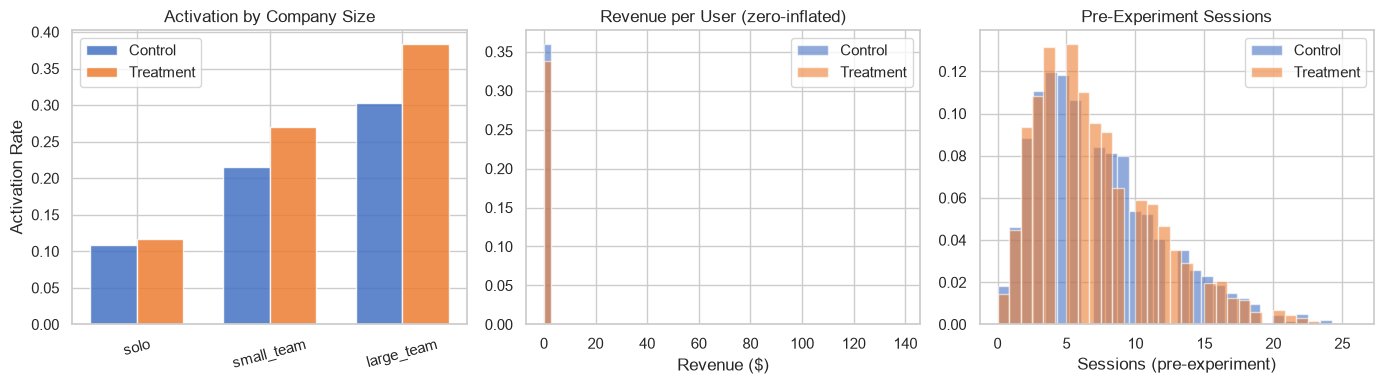

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Activation rate by segment
seg_rates = df.groupby(['company_size', 'variant'])['activated'].mean().unstack()
size_order = ['solo', 'small_team', 'large_team']
seg_rates = seg_rates.loc[size_order]
x = np.arange(len(size_order))
width = 0.35
axes[0].bar(x - width/2, seg_rates['control'],   width, label='Control',   color='#4472C4', alpha=0.85)
axes[0].bar(x + width/2, seg_rates['treatment'], width, label='Treatment', color='#ED7D31', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(size_order, rotation=15)
axes[0].set_ylabel('Activation Rate')
axes[0].set_title('Activation by Company Size')
axes[0].legend()

# Revenue distribution (log scale preview)
axes[1].hist(ctrl['revenue'],  bins=50, alpha=0.6, color='#4472C4', label='Control',   density=True)
axes[1].hist(trt['revenue'],   bins=50, alpha=0.6, color='#ED7D31', label='Treatment', density=True)
axes[1].set_xlabel('Revenue ($)')
axes[1].set_title('Revenue per User (zero-inflated)')
axes[1].legend()

# Pre-exp sessions
axes[2].hist(ctrl['pre_exp_sessions'],  bins=30, alpha=0.6, color='#4472C4', label='Control',   density=True)
axes[2].hist(trt['pre_exp_sessions'],   bins=30, alpha=0.6, color='#ED7D31', label='Treatment', density=True)
axes[2].set_xlabel('Sessions (pre-experiment)')
axes[2].set_title('Pre-Experiment Sessions')
axes[2].legend()

plt.tight_layout()
plt.show()

## Fixed-horizon activation test

395/2,115 versus 482/2,115 gives +4.1135 pp or +22.03% relative lift, p=.000968 and an approximate Wald difference interval +1.67 to +6.55 pp. This is estimation on generated outcomes.


In [7]:
z_result = two_proportion_ztest(
    ctrl['activated'], trt['activated'], alpha=exp['alpha']
)

print("=" * 55)
print("PRIMARY METRIC: Week-1 Activation Rate")
print("=" * 55)
print(f"  Control rate     : {z_result['control_mean']:.2%}")
print(f"  Treatment rate   : {z_result['treatment_mean']:.2%}")
print(f"  Absolute lift    : {z_result['absolute_lift']*100:+.2f} pp")
print(f"  Relative lift    : {z_result['relative_lift_pct']:+.1f}%")
print(f"  95% CI (absolute): [{z_result['ci_lower']:+.2%}, {z_result['ci_upper']:+.2%}]")
print(f"  z-statistic      : {z_result['z_stat']:.3f}")
print(f"  p-value          : {z_result['p_value']:.4f}")
print(f"  Significant?     : {'YES ✓' if z_result['significant'] else 'NO ✗'}")
print()
print("Interpretation:")
if z_result['significant']:
    print(f"  The generated treatment estimates activation higher by {z_result['relative_lift_pct']:.1f}% relative")
    print(f"  (95% CI: {z_result['ci_lower']*100:+.1f} to {z_result['ci_upper']*100:+.1f} pp absolute).")
    print(f"  This is statistically significant at α = {exp['alpha']}.")
else:
    print("  No significant effect detected at the current sample size.")

PRIMARY METRIC: Week-1 Activation Rate
  Control rate     : 18.68%
  Treatment rate   : 22.79%
  Absolute lift    : +4.11 pp
  Relative lift    : +22.0%
  95% CI (absolute): [+1.67%, +6.55%]
  z-statistic      : 3.300
  p-value          : 0.0010
  Significant?     : YES ✓

Interpretation:
  The generated treatment estimates activation higher by 22.0% relative
  (95% CI: +1.7 to +6.6 pp absolute).
  This is statistically significant at α = 0.05.


## Exploratory subgroup estimates

Company-size variation is planted. Separate subgroup p-values are unadjusted and do not test interaction. Prelisting dimensions does not remove multiplicity. Nonsignificance does not show equivalence. Relative intervals rescale absolute intervals by the estimated control rate and omit denominator uncertainty. Use absolute intervals for inference. Channel differences arise from sampling variation.


=== Segment Analysis: company_size ===
   segment  n_control  control_rate  treatment_rate  rel_lift_pct  p_value  significant
large_team        330        0.3030          0.3829       26.4000   0.0324         True
small_team        945        0.2159          0.2697       24.9000   0.0058         True
      solo        840        0.1083          0.1162        7.2000   0.6132        False
Saved → outputs/segment_forest_size.png


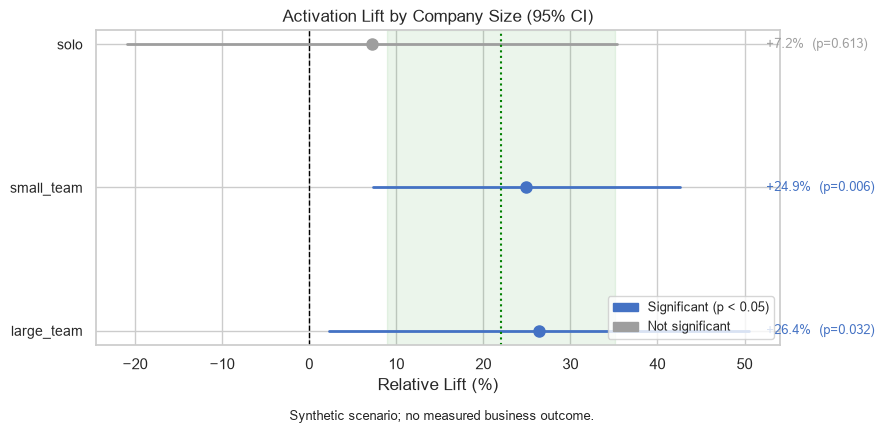

In [8]:
seg_size = segment_analysis(
    df, 'company_size', 'activated', metric_type='binary'
)

print("=== Segment Analysis: company_size ===")
cols = ['segment','n_control','control_rate','treatment_rate','rel_lift_pct','p_value','significant']
print(seg_size[cols].to_string(index=False))

overall_rel_lift  = z_result['relative_lift_pct']
overall_ci        = (
    z_result['ci_lower'] / z_result['control_mean'] * 100,
    z_result['ci_upper'] / z_result['control_mean'] * 100,
)

fig = plot_segment_forest(
    seg_size,
    title='Activation Lift by Company Size (95% CI)',
    overall_lift=overall_rel_lift,
    overall_ci=overall_ci,
    save_path=OUTPUTS / 'segment_forest_size.png',
)
plt.show()
print("Saved → outputs/segment_forest_size.png")

=== Segment Analysis: acquisition_channel ===
 segment  n_control  control_rate  treatment_rate  rel_lift_pct  p_value  significant
 organic       1064        0.1936          0.2385       23.2000   0.0119         True
    paid        740        0.1784          0.2236       25.3000   0.0297         True
referral        311        0.1833          0.2013        9.8000   0.5706        False
Saved → outputs/segment_forest_channel.png


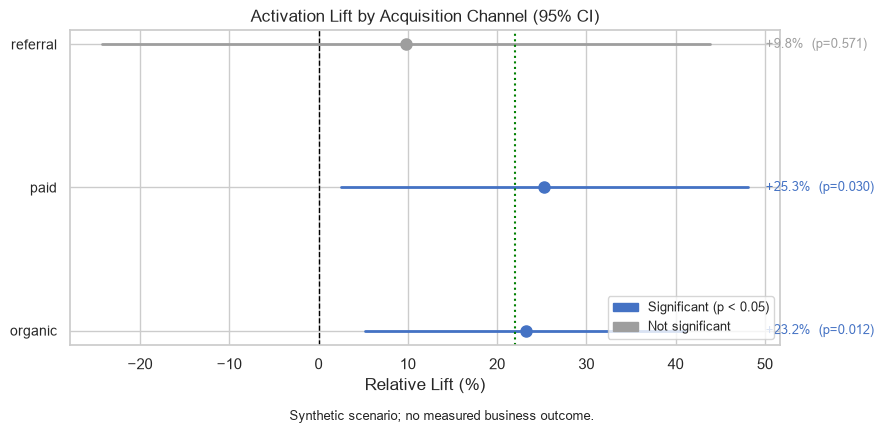

In [9]:
seg_channel = segment_analysis(
    df, 'acquisition_channel', 'activated', metric_type='binary'
)

print("=== Segment Analysis: acquisition_channel ===")
print(seg_channel[cols].to_string(index=False))

fig = plot_segment_forest(
    seg_channel,
    title='Activation Lift by Acquisition Channel (95% CI)',
    overall_lift=overall_rel_lift,
    save_path=OUTPUTS / 'segment_forest_channel.png',
)
plt.show()
print("Saved → outputs/segment_forest_channel.png")

## Generated revenue

Revenue is zero-inflated. Saved group means are $2.8456 and $3.2665; Welch p=.326835. The result establishes neither benefit nor equivalence, and no acquisition-channel mechanism is encoded.


In [10]:
t_result = welch_ttest(
    ctrl['revenue'], trt['revenue'],
    alpha=exp['alpha'],
    metric_name='revenue_per_user',
)

print("=" * 55)
print("SECONDARY METRIC: Revenue Per User")
print("=" * 55)
print(f"  Control mean     : ${t_result['control_mean']:.2f}")
print(f"  Treatment mean   : ${t_result['treatment_mean']:.2f}")
print(f"  Absolute lift    : ${t_result['absolute_lift']:+.2f}")
print(f"  Relative lift    : {t_result['relative_lift_pct']:+.1f}%")
print(f"  95% CI           : [${t_result['ci_lower']:+.2f}, ${t_result['ci_upper']:+.2f}]")
print(f"  t-statistic      : {t_result['t_stat']:.3f}")
print(f"  p-value          : {t_result['p_value']:.4f}")
print(f"  Significant?     : {'YES ✓' if t_result['significant'] else 'NO ✗'}")
print()
print("Zero-inflation breakdown:")
for v, grp in [('Control', ctrl), ('Treatment', trt)]:
    pct_zero  = (grp['revenue'] == 0).mean()
    pct_paid  = (grp['revenue'] > 0).mean()
    avg_among_paid = grp.loc[grp['revenue'] > 0, 'revenue'].mean()
    print(f"  {v}: {pct_zero:.1%} at $0, {pct_paid:.1%} paying, avg paid = ${avg_among_paid:.2f}")

SECONDARY METRIC: Revenue Per User
  Control mean     : $2.85
  Treatment mean   : $3.27
  Absolute lift    : $+0.42
  Relative lift    : +14.8%
  95% CI           : [$-0.42, $+1.26]
  t-statistic      : -0.981
  p-value          : 0.3268
  Significant?     : NO ✗

Zero-inflation breakdown:
  Control: 94.8% at $0, 5.2% paying, avg paid = $55.22
  Treatment: 94.0% at $0, 6.0% paying, avg paid = $54.40


Saved → outputs/revenue_distribution.png


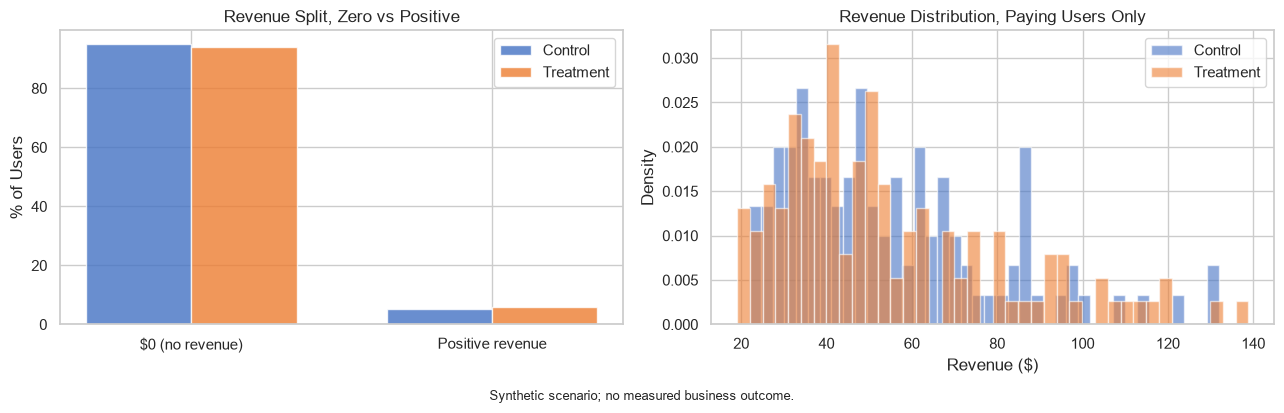

In [11]:
fig = plot_revenue_distribution(
    ctrl['revenue'], trt['revenue'],
    save_path=OUTPUTS / 'revenue_distribution.png',
)
plt.show()
print("Saved → outputs/revenue_distribution.png")

## Generated guardrail

Drop-off increases by 5.3428 pp, p=.000288. It is sampled separately from activation and does not establish an observed funnel or actual churn mechanism. A nonsignificant harm test would not by itself establish safety.


In [12]:
guardrail_result = two_proportion_ztest(
    ctrl['day1_dropoff'], trt['day1_dropoff'], alpha=exp['alpha']
)

print("=" * 55)
print("GUARDRAIL: Day-1 Drop-off Rate")
print("=" * 55)
print(f"  Control drop-off   : {guardrail_result['control_mean']:.2%}")
print(f"  Treatment drop-off : {guardrail_result['treatment_mean']:.2%}")
print(f"  Absolute change    : {guardrail_result['absolute_lift']*100:+.2f} pp")
print(f"  p-value            : {guardrail_result['p_value']:.4f}")
print(f"  Significant?       : {'YES' if guardrail_result['significant'] else 'NO'}")
print()

if guardrail_result['significant'] and guardrail_result['absolute_lift'] > 0:
    print("⚠️  GUARDRAIL ALERT: Day-1 drop-off is significantly HIGHER in treatment.")
    print(f"   Generated drop-off is higher by {guardrail_result['absolute_lift']*100:.1f} pp.")
    print("   This must be weighed against the primary activation gain.")
else:
    print("✓  No significant increase detected; this does not establish safety.")

GUARDRAIL: Day-1 Drop-off Rate
  Control drop-off   : 33.05%
  Treatment drop-off : 38.39%
  Absolute change    : +5.34 pp
  p-value            : 0.0003
  Significant?       : YES

⚠️  GUARDRAIL ALERT: Day-1 drop-off is significantly HIGHER in treatment.
   Generated drop-off is higher by 5.3 pp.
   This must be weighed against the primary activation gain.


## Retrospective interim-look illustration

This function compares pointwise p-values with cumulative spending expressions. It is not a calibrated group-sequential boundary procedure and does not establish overall alpha control. Its Pocock-labelled branch is linear, not a calibrated Pocock design. The saved path crosses at look 7 and 2,954 records. Floor-sized batches omit five records per arm at the final look and rounded p-values are used. This path cannot support early stopping or time-saving claims.


Sequential test results:
 look  n_cumulative  p_value  alpha_boundary  significant  relative_lift_pct
    1           422   0.8121          0.0000        False             4.5500
    2           844   0.3582          0.0000        False            12.7900
    3          1266   0.6333          0.0003        False             5.2200
    4          1688   0.0345          0.0019        False            21.4300
    5          2110   0.0273          0.0056        False            19.9100
    6          2532   0.0340          0.0114        False            17.3900
    7          2954   0.0075          0.0192         True            20.5500

✓ Illustrative path crosses at look 7 (2,954 generated records, 70% of planned N).
Saved → outputs/sequential_test.png


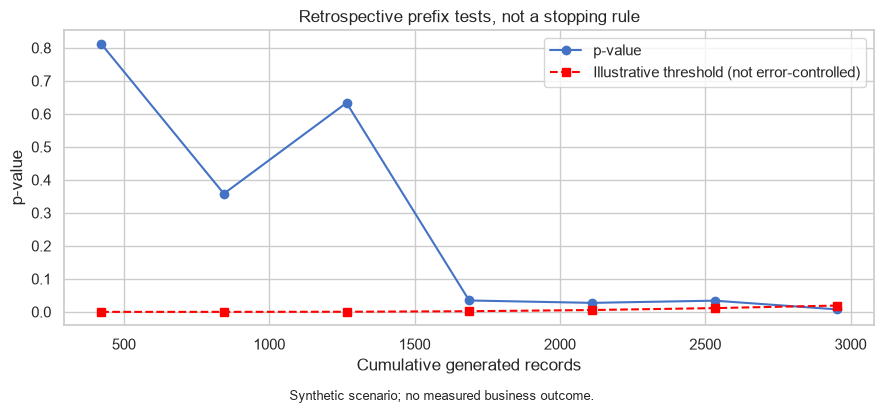

In [13]:
seq_df = sequential_test(
    ctrl['activated'].reset_index(drop=True),
    trt['activated'].reset_index(drop=True),
    max_looks=seq['max_looks'],
    alpha=exp['alpha'],
    spending_fn=seq['alpha_spending'],
)

print("Sequential test results:")
print(seq_df.to_string(index=False))
print()

if seq_df['significant'].any():
    stop_look = seq_df[seq_df['significant']].iloc[0]
    print(f"✓ Illustrative path crosses at look {int(stop_look['look'])} "
          f"({int(stop_look['n_cumulative']):,} generated records, "
          f"{int(stop_look['n_cumulative'])/n_users*100:.0f}% of planned N).")
else:
    print("Did not cross the illustrative threshold. No repeated-testing guarantee.")

fig = plot_sequential_path(seq_df, save_path=OUTPUTS / 'sequential_test.png')
plt.show()
print("Saved → outputs/sequential_test.png")

## Assumed-prior Bayesian analysis

Beta(18,82) is an assumed prior with mean .18 and concentration 100, not an evidenced industry benchmark. Saved 100,000-draw results are conditional on this prior/model. ROPE compares the absolute difference with +.005 at posterior probability .95; that chosen threshold is not a measured commercial benefit.


In [14]:
bayes_result = probability_treatment_better(
    ctrl['activated'], trt['activated'],
    prior_alpha=bay['prior_alpha'],
    prior_beta=bay['prior_beta'],
    n_samples=bay['n_samples'],
    seed=42,
)

rope_result = rope_decision(
    ctrl['activated'], trt['activated'],
    rope_width=bay['rope_width'],
    prior_alpha=bay['prior_alpha'],
    prior_beta=bay['prior_beta'],
    n_samples=bay['n_samples'],
    seed=42,
)

print("=" * 55)
print("BAYESIAN ANALYSIS")
print("=" * 55)
print(f"  Prior                : Beta({bay['prior_alpha']:.0f}, {bay['prior_beta']:.0f})  [mean = {bay['prior_alpha']/(bay['prior_alpha']+bay['prior_beta']):.1%}]")
print(f"  P(treatment > control): {bayes_result['prob_treatment_better']:.1%}")
print(f"  Expected lift         : {bayes_result['expected_relative_lift_pct']:+.1f}%")
lo, hi = bayes_result['lift_95pct_credible_interval']
print(f"  95% Credible Interval : [{lo:+.1f}%, {hi:+.1f}%]")
print()
print("=" * 55)
print("ROPE DECISION")
print("=" * 55)
print(f"  ROPE width            : ±{bay['rope_width']:.3f} (±{bay['rope_width']*100:.1f} pp)")
print(f"  P(treatment wins)     : {rope_result['p_treatment_wins']:.1%}")
print(f"  P(equivalent)         : {rope_result['p_equivalent_rope']:.1%}")
print(f"  P(control wins)       : {rope_result['p_control_wins']:.1%}")
print(f"  Decision              : {rope_result['decision'].upper()}")

BAYESIAN ANALYSIS
  Prior                : Beta(18, 82)  [mean = 18.0%]
  P(treatment > control): 99.9%
  Expected lift         : +21.3%
  95% Credible Interval : [+7.8%, +36.1%]

ROPE DECISION
  ROPE width            : ±0.005 (±0.5 pp)
  P(treatment wins)     : 99.7%
  P(equivalent)         : 0.3%
  P(control wins)       : 0.0%
  Decision              : TREATMENT_WINS


Saved → outputs/posterior_lift.png


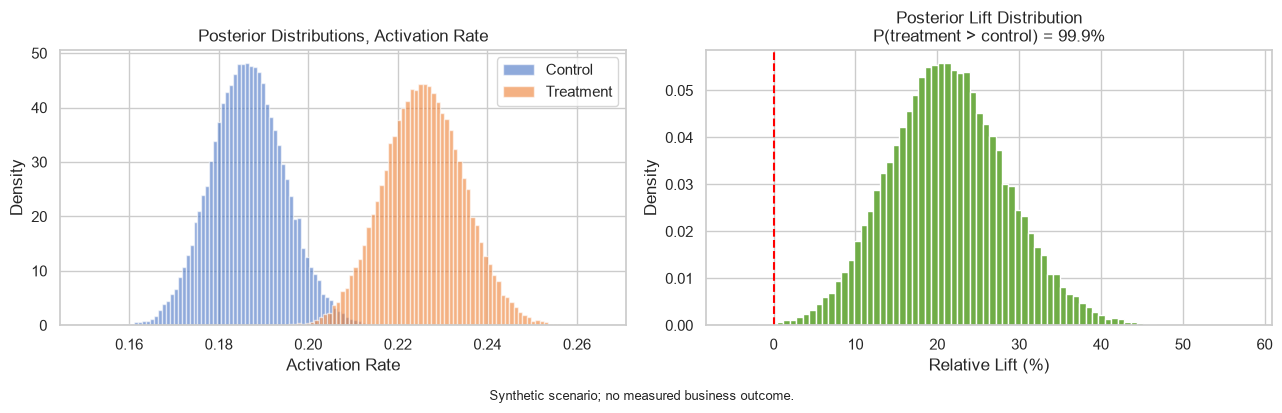

In [15]:
rng = np.random.default_rng(0)
ctrl_samples = rng.beta(*bayes_result['control_posterior'], size=50_000)
trt_samples  = rng.beta(*bayes_result['treatment_posterior'], size=50_000)

fig = plot_posterior(
    ctrl_samples, trt_samples,
    prob_better=bayes_result['prob_treatment_better'],
    save_path=OUTPUTS / 'posterior_lift.png',
)
plt.show()
print("Saved → outputs/posterior_lift.png")

## Pooled covariate adjustment

CUPED projects revenue onto centred covariates. Pooled variance reduction of 4.34% implies about 4.54% equivalent N under equal-estimator assumptions. Pooled centring preserves the pooled mean, not the arm difference. Squared marginal correlations are not additive contributions. The adjusted Welch analysis does not fully account for adjustment estimation and is provisional.


In [16]:
covariates = ['pre_exp_sessions', 'pre_exp_feature_depth']

vr_stats = cuped_variance_reduction_multi(df, 'revenue', covariates)

print("=" * 55)
print("CUPED, Multi-Covariate Variance Reduction")
print("=" * 55)
print(f"  Variance (original) : {vr_stats['variance_original']:.4f}")
print(f"  Variance (CUPED)    : {vr_stats['variance_cuped']:.4f}")
print(f"  Reduction           : {vr_stats['reduction_pct']:.1f}%")
print(f"  Effective sample gain: {vr_stats['effective_sample_gain_pct']:.1f}%")
print()
for col, r in vr_stats['pearson_r_per_covariate'].items():
    print(f"  Pearson r ({col:30s}): {r:+.4f}  (marginal r squared = {r**2:.1%}; not an additive contribution)")
print()

# Re-run Welch t-test on CUPED-adjusted revenue
df_adj   = apply_cuped_multi(df, 'revenue', covariates)
ctrl_adj = df_adj[df_adj['variant'] == 'control']
trt_adj  = df_adj[df_adj['variant'] == 'treatment']

t_cuped = welch_ttest(
    ctrl_adj['revenue_cuped'], trt_adj['revenue_cuped'],
    alpha=exp['alpha'],
    metric_name='revenue_cuped',
)

print("Effect on revenue t-test:")
print(f"  Original p-value : {t_result['p_value']:.4f}")
print(f"  CUPED p-value    : {t_cuped['p_value']:.4f}")
print(f"  Original 95% CI  : [${t_result['ci_lower']:+.2f}, ${t_result['ci_upper']:+.2f}]")
print(f"  CUPED 95% CI     : [${t_cuped['ci_lower']:+.2f}, ${t_cuped['ci_upper']:+.2f}]")
print()
print("Note: CUPED preserves the pooled mean; the arm contrast can change. Adjusted Welch inference is provisional.")

CUPED, Multi-Covariate Variance Reduction
  Variance (original) : 194.8082
  Variance (CUPED)    : 186.3517
  Reduction           : 4.3%
  Effective sample gain: 4.5%

  Pearson r (pre_exp_sessions              ): +0.1957  (marginal r squared = 3.8%; not an additive contribution)
  Pearson r (pre_exp_feature_depth         ): +0.1906  (marginal r squared = 3.6%; not an additive contribution)

Effect on revenue t-test:
  Original p-value : 0.3268
  CUPED p-value    : 0.2435
  Original 95% CI  : [$-0.42, $+1.26]
  CUPED 95% CI     : [$-0.33, $+1.31]

Note: CUPED preserves the pooled mean; the arm contrast can change. Adjusted Welch inference is provisional.


## Fixed-horizon Monte Carlo check

200 simulations per setting give 8/200 null and 157/200 alternative rejections. Approximate Wilson 95% intervals are 2.04% to 7.69% and 72.30% to 83.63%. These exercise fixed-horizon tests, not sequential stopping. The config value is a simulation setting, not evidence of a production experiment.


Running 200 simulations under H₀ ...
Running 200 simulations under H₁ (lift = 20%) ...

Type I error (H₀): 4.0%  (target: 5%)
Empirical power  (H₁): 78.5%  (target: 80%)
Saved → outputs/pvalue_sim_distribution.png


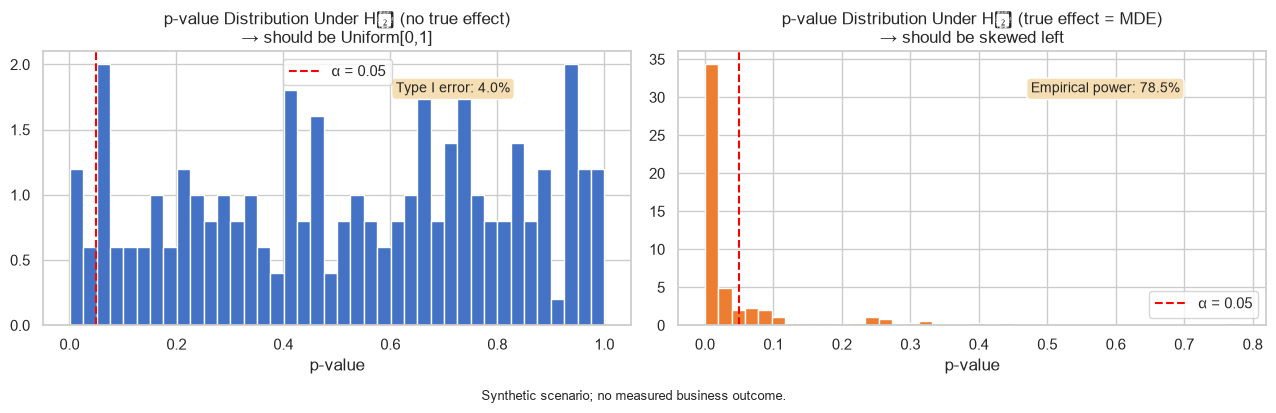

In [17]:
N_CALIB_SIMS = min(200, exp['n_simulations'])   # cap for notebook runtime (~30-60s)

print(f"Running {N_CALIB_SIMS} simulations under H₀ ...")
pvals_h0 = simulate_pvalue_distribution(
    n_users=n_required * 2,
    baseline_activation_rate=exp['baseline_activation_rate'],
    true_lift=0.0,
    n_simulations=N_CALIB_SIMS,
    seed=0,
)

print(f"Running {N_CALIB_SIMS} simulations under H₁ (lift = {exp['mde']:.0%}) ...")
pvals_h1 = simulate_pvalue_distribution(
    n_users=n_required * 2,
    baseline_activation_rate=exp['baseline_activation_rate'],
    true_lift=exp['mde'],
    n_simulations=N_CALIB_SIMS,
    seed=1000,
)

type_i = (pvals_h0 < exp['alpha']).mean()
power  = (pvals_h1 < exp['alpha']).mean()

print(f"\nType I error (H₀): {type_i:.1%}  (target: {exp['alpha']:.0%})")
print(f"Empirical power  (H₁): {power:.1%}  (target: {exp['power']:.0%})")

fig = plot_pvalue_distribution(
    pvals_h0, pvals_h1,
    alpha=exp['alpha'],
    save_path=OUTPUTS / 'pvalue_sim_distribution.png',
)
plt.show()
print("Saved → outputs/pvalue_sim_distribution.png")

## Hypothetical decision limits

Activation favours treatment, revenue is uncertain and drop-off worsens in generated data. No team rollout is justified by overall significance or a nonsignificant solo estimate. A hypothetical follow-up needs a harm criterion, segment guardrails and independent confirmation.


Saved → outputs/metric_scorecard.png


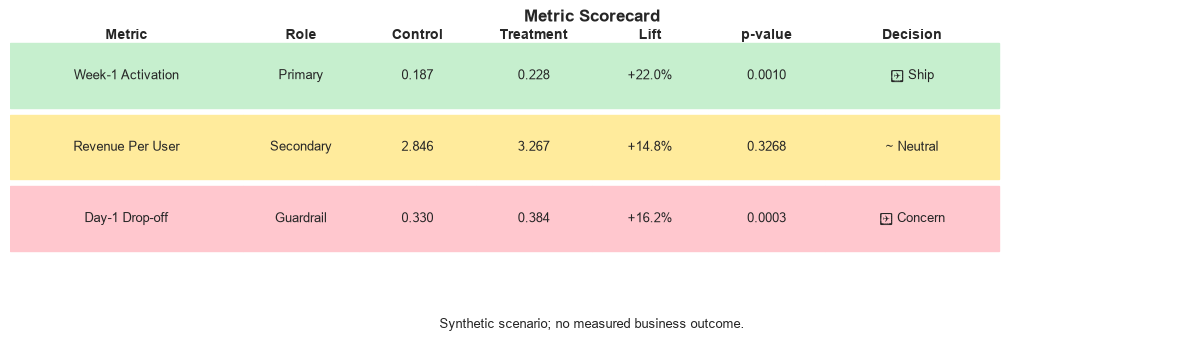

In [18]:
scorecard_data = [
    {
        'label':          'Week-1 Activation',
        'role':           'primary',
        'control_mean':   z_result['control_mean'],
        'treatment_mean': z_result['treatment_mean'],
        'rel_lift_pct':   z_result['relative_lift_pct'],
        'p_value':        z_result['p_value'],
        'significant':    z_result['significant'],
        'direction':      'higher_better',
    },
    {
        'label':          'Revenue Per User',
        'role':           'secondary',
        'control_mean':   t_result['control_mean'],
        'treatment_mean': t_result['treatment_mean'],
        'rel_lift_pct':   t_result['relative_lift_pct'],
        'p_value':        t_result['p_value'],
        'significant':    t_result['significant'],
        'direction':      'higher_better',
    },
    {
        'label':          'Day-1 Drop-off',
        'role':           'guardrail',
        'control_mean':   guardrail_result['control_mean'],
        'treatment_mean': guardrail_result['treatment_mean'],
        'rel_lift_pct':   guardrail_result['relative_lift_pct'],
        'p_value':        guardrail_result['p_value'],
        'significant':    guardrail_result['significant'],
        'direction':      'lower_better',
    },
]

fig = plot_metric_scorecard(scorecard_data, save_path=OUTPUTS / 'metric_scorecard.png')
plt.show()
print("Saved → outputs/metric_scorecard.png")

In [19]:
print("Synthetic decision summary")
print("Activation favours treatment; revenue remains uncertain; generated drop-off worsens.")
print("No team rollout is established. Separate subgroup p-values do not test interaction.")
print("A hypothetical next evaluation needs segment guardrails, a harm criterion and independent confirmation.")


Synthetic decision summary
Activation favours treatment; revenue remains uncertain; generated drop-off worsens.
No team rollout is established. Separate subgroup p-values do not test interaction.
A hypothetical next evaluation needs segment guardrails, a harm criterion and independent confirmation.


In [20]:
run_summary = {
    "schema_version": 2,
    "sequential_status": "retrospective illustrative threshold; alpha control not established",
    "schema_version": 2,
    "sequential_status": "retrospective illustrative threshold; alpha control not established",
    'experiment_name':      exp['name'],
    'n_users_total':        len(df),
    'n_required_per_group': n_required,
    'true_lift_planted':    TRUE_LIFT,
    'primary_metric': {
        'metric':            'activation_rate',
        'control_mean':      z_result['control_mean'],
        'treatment_mean':    z_result['treatment_mean'],
        'relative_lift_pct': z_result['relative_lift_pct'],
        'p_value':           z_result['p_value'],
        'significant':       z_result['significant'],
    },
    'secondary_metric': {
        'metric':            'revenue_per_user',
        'control_mean':      t_result['control_mean'],
        'treatment_mean':    t_result['treatment_mean'],
        'relative_lift_pct': t_result['relative_lift_pct'],
        'p_value':           t_result['p_value'],
        'significant':       t_result['significant'],
    },
    'guardrail_metric': {
        'metric':            'day1_dropoff',
        'control_mean':      guardrail_result['control_mean'],
        'treatment_mean':    guardrail_result['treatment_mean'],
        'absolute_change': guardrail_result['absolute_lift'],
        'absolute_change_pp': guardrail_result['absolute_lift'] * 100,
        'p_value':           guardrail_result['p_value'],
        'breached':          bool(guardrail_result['significant'] and guardrail_result['absolute_lift'] > 0),
    },
    'bayesian': {
        'prob_treatment_better':  bayes_result['prob_treatment_better'],
        'expected_lift_pct':      bayes_result['expected_relative_lift_pct'],
        'credible_interval_95':   bayes_result['lift_95pct_credible_interval'],
        'rope_decision':          rope_result['decision'],
    },
    'cuped': {
        'variance_reduction_pct':    vr_stats['reduction_pct'],
        'effective_sample_gain_pct': vr_stats['effective_sample_gain_pct'],
    },
    'segment_analysis': seg_size[['segment','rel_lift_pct','p_value','significant']].to_dict(orient='records'),
    'calibration': {
        'type_i_error':   round(float(type_i), 4),
        'empirical_power': round(float(power), 4),
    },
}

(OUTPUTS / 'run_summary.json').write_text(json.dumps(run_summary, indent=2, default=str))
print('run_summary.json saved to outputs/')
print(json.dumps(run_summary, indent=2, default=str))

run_summary.json saved to outputs/
{
  "schema_version": 2,
  "sequential_status": "retrospective illustrative threshold; alpha control not established",
  "experiment_name": "saas_onboarding_wizard",
  "n_users_total": 4230,
  "n_required_per_group": 1923,
  "true_lift_planted": 0.25,
  "primary_metric": {
    "metric": "activation_rate",
    "control_mean": 0.186761,
    "treatment_mean": 0.227896,
    "relative_lift_pct": 22.03,
    "p_value": 0.000968,
    "significant": true
  },
  "secondary_metric": {
    "metric": "revenue_per_user",
    "control_mean": 2.8456,
    "treatment_mean": 3.2665,
    "relative_lift_pct": 14.79,
    "p_value": 0.326835,
    "significant": false
  },
  "guardrail_metric": {
    "metric": "day1_dropoff",
    "control_mean": 0.330496,
    "treatment_mean": 0.383924,
    "absolute_change": 0.053428,
    "absolute_change_pp": 5.3428,
    "p_value": 0.000288,
    "breached": true
  },
  "bayesian": {
    "prob_treatment_better": 0.9993,
    "expected_lift_p